# Module 8 - Regression Modeling on the Auto MPG Dataset

Goal: predict a car's fuel efficiency (`mpg`) from its technical attributes with a Random Forest regressor.

## Import Libraries

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Load Dataset

In [2]:
df = pd.read_csv(Path('../data/auto-mpg.csv'))
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


## Data Understanding

In [3]:
print("Dataset info:")
df.info()

Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    str    
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    str    
dtypes: float64(3), int64(4), str(2)
memory usage: 28.1 KB


In [4]:
print("Descriptive statistics:")
df.describe()

Descriptive statistics:


,mpg,cylinders,displacement,weight,acceleration,model year,origin
count,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,5140.000000,24.800000,82.000000,3.000000


In [5]:
cylinders_values = df['cylinders'].unique()
print(f"Unique values in the cylinders column: {cylinders_values}")

Unique values in the cylinders column: [8 4 6 3 5]


In [6]:
horsepower_values = df['horsepower'].unique()
print(f"Sample of unique values in the horsepower column: {horsepower_values[20:30]}...")

Sample of unique values in the horsepower column: <StringArray>
['210', '193', '?', '100', '105', '175', '153', '180', '110', '72']
Length: 10, dtype: str...


## Preprocessing

1. `horsepower` is stored as text because it contains `'?'`; convert those to `NaN`, cast to float, and fill the 6 missing values with the median (the distribution is right-skewed, so the median is more robust than the mean).
2. Map `origin` codes (1, 2, 3) to readable labels for EDA.
3. Drop `car name`, a unique identifier that is not a useful predictor.

In [7]:
df['horsepower'] = df['horsepower'].replace('?', np.nan)
df['horsepower'] = df['horsepower'].astype(float)

print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64


In [8]:
median_hp = df['horsepower'].median()
df['horsepower'] = df['horsepower'].fillna(median_hp)

print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64


In [9]:
origin_map = {1: 'USA', 2: 'Europe', 3: 'Japan'}
df['origin'] = df['origin'].map(origin_map)

print("Data after mapping the 'origin' column:")
df.head()

Data after mapping the 'origin' column:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130.0,3504,12.0,70,USA,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,USA,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,USA,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,USA,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,USA,ford torino


In [10]:
df_cleaned = df.drop('car name', axis=1)

print("Data after dropping 'car name':")
df_cleaned.head()

Data after dropping 'car name':


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin
0,18.0,8,307.0,130.0,3504,12.0,70,USA
1,15.0,8,350.0,165.0,3693,11.5,70,USA
2,18.0,8,318.0,150.0,3436,11.0,70,USA
3,16.0,8,304.0,150.0,3433,12.0,70,USA
4,17.0,8,302.0,140.0,3449,10.5,70,USA


In [11]:
print("Dataset info after preprocessing:")
df_cleaned.info()

Dataset info after preprocessing:
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    str    
dtypes: float64(4), int64(3), str(1)
memory usage: 25.0 KB


## Exploratory Data Analysis (EDA)

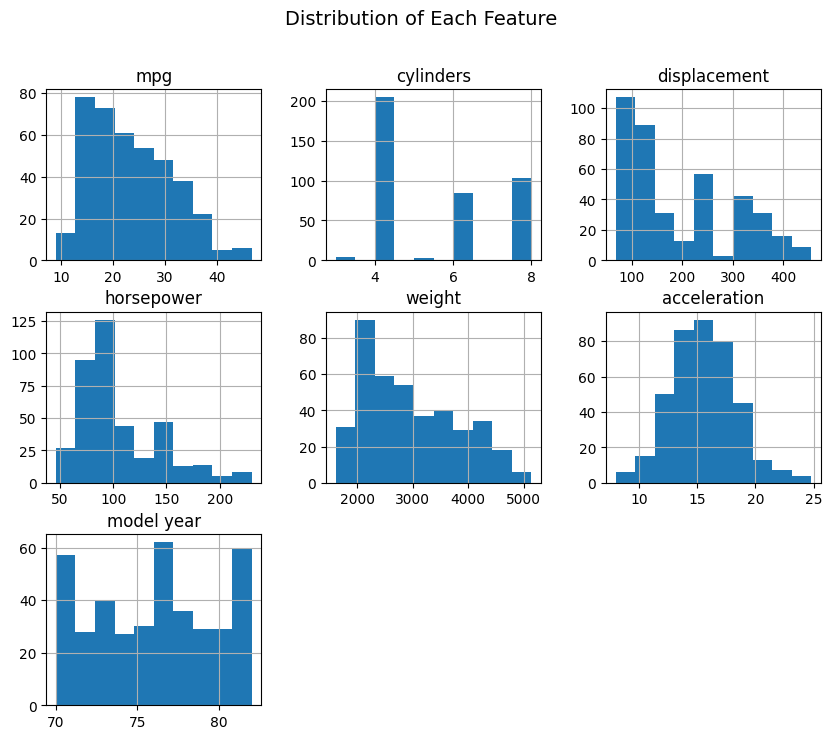

In [12]:
df_cleaned.hist(figsize=(10, 8))
plt.suptitle("Distribution of Each Feature", fontsize=14)
plt.show()

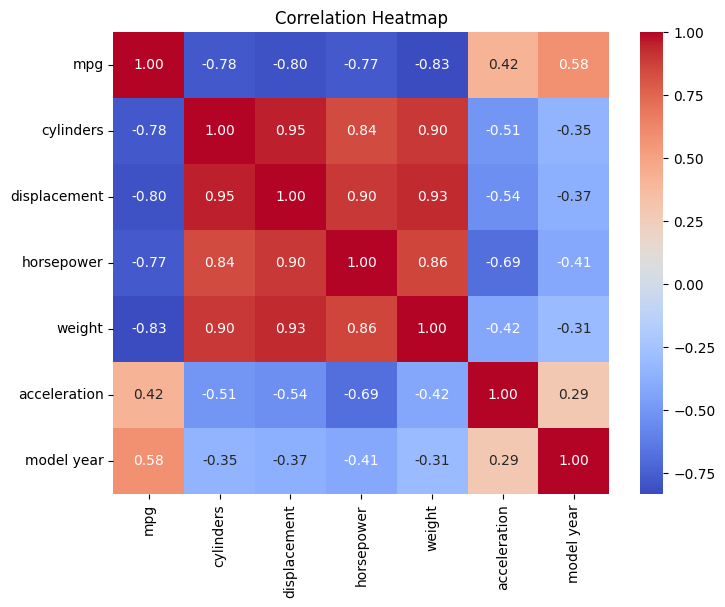

In [13]:
corr = df_cleaned.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

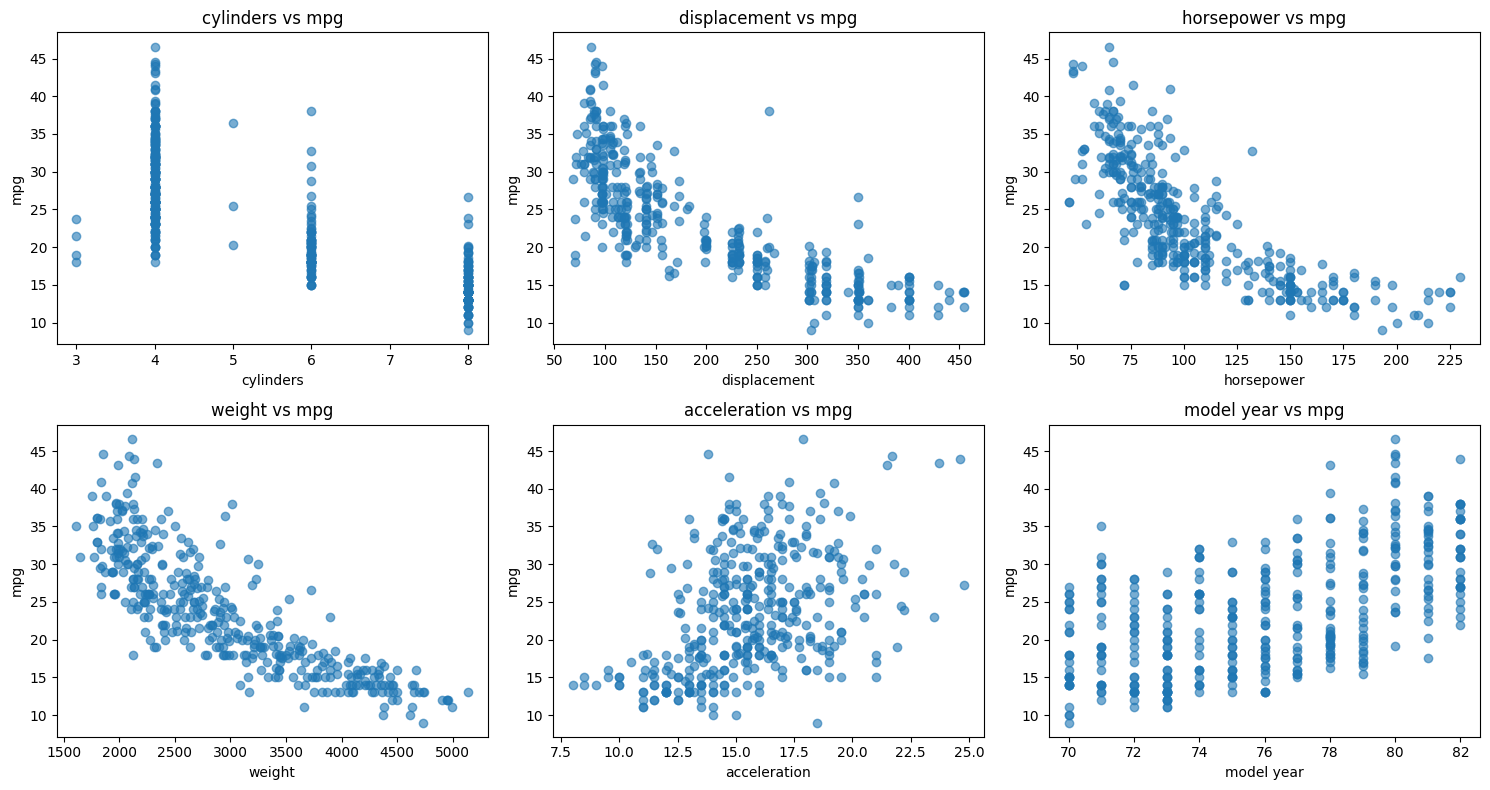

In [14]:
features = ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year']
target = 'mpg'

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, col in enumerate(features):
    ax = axes[i // 3, i % 3]
    ax.scatter(df_cleaned[col], df_cleaned[target], alpha=0.6)
    ax.set_xlabel(col)
    ax.set_ylabel(target)
    ax.set_title(f'{col} vs {target}')

plt.tight_layout()
plt.show()

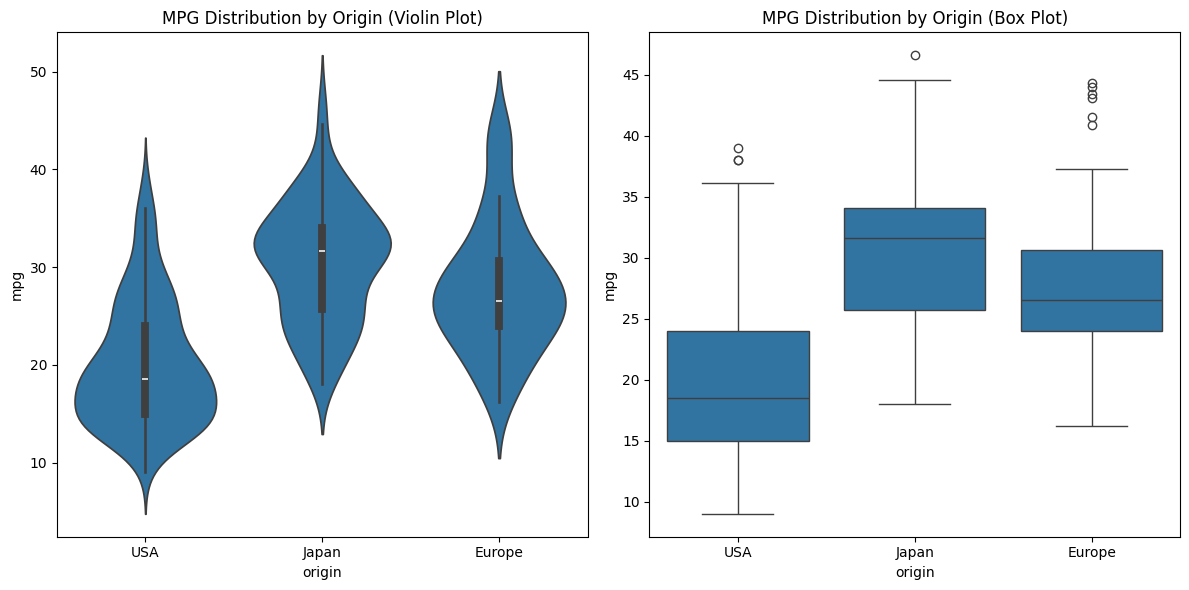

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

sns.violinplot(x='origin', y='mpg', data=df_cleaned, ax=axes[0])
axes[0].set_title('MPG Distribution by Origin (Violin Plot)')

sns.boxplot(x='origin', y='mpg', data=df_cleaned, ax=axes[1])
axes[1].set_title('MPG Distribution by Origin (Box Plot)')

plt.tight_layout()
plt.show()

## Modeling

Selected predictors: `weight` (strongest correlation with `mpg`), `horsepower`, `model year`, and `origin`. `displacement` and `cylinders` overlap heavily with `weight` and `horsepower`; `acceleration` has the weakest correlation. Random Forest is robust to multicollinearity and does not require feature scaling.

In [16]:
le = LabelEncoder()
df_cleaned['origin'] = le.fit_transform(df_cleaned['origin'])

X = df_cleaned[['origin', 'model year', 'horsepower', 'weight']]
y = df_cleaned['mpg']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features shape:", X_train.shape)
print("Training labels shape:", y_train.shape)
print("Test features shape:", X_test.shape)
print("Test labels shape:", y_test.shape)

Training features shape: (318, 4)
Training labels shape: (318,)
Test features shape: (80, 4)
Test labels shape: (80,)


In [17]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=None, n_jobs=-1)

rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

## Evaluation

In [18]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2): {r2:.2f}")

Mean Absolute Error (MAE): 1.70
Mean Squared Error (MSE): 4.67
Root Mean Squared Error (RMSE): 2.16
R-squared (R2): 0.91
